# Real-Time UPI Fraud Detection
## Exploratory Data Analysis (EDA)

### Objective
Analyze UPI transactions to:
- Assess dataset quality and reliability.
- Identify potential data leakage.
- Understand fraud class imbalance.
- Demonstrate why accuracy is misleading.
- Investigate fraud patterns across transaction types, amounts, and time.

**Dataset:** UPI Transactions 2024

**Hackathon:** KLU+Path-3 | ML-02

## 0. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:\\Users\\ASUS\\Downloads\\fradudetectionbank\\21015299-upi_transactions_2024\\upi_transactions 2024.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (250000, 17)


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [3]:
# Dataset structure
df.info()

# Missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

# Duplicate records
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate transaction IDs:", df["transaction id"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   transaction id      250000 non-null  str  
 1   timestamp           250000 non-null  str  
 2   transaction type    250000 non-null  str  
 3   merchant_category   250000 non-null  str  
 4   amount (INR)        250000 non-null  int64
 5   transaction_status  250000 non-null  str  
 6   sender_age_group    250000 non-null  str  
 7   receiver_age_group  250000 non-null  str  
 8   sender_state        250000 non-null  str  
 9   sender_bank         250000 non-null  str  
 10  receiver_bank       250000 non-null  str  
 11  device_type         250000 non-null  str  
 12  network_type        250000 non-null  str  
 13  fraud_flag          250000 non-null  int64
 14  hour_of_day         250000 non-null  int64
 15  day_of_week         250000 non-null  str  
 16  is_weekend          250000 non-

,Missing Count,Missing %
transaction id,0,0.0
timestamp,0,0.0
transaction type,0,0.0
merchant_category,0,0.0
amount (INR),0,0.0
transaction_status,0,0.0
sender_age_group,0,0.0
receiver_age_group,0,0.0
sender_state,0,0.0
sender_bank,0,0.0


Duplicate rows: 0
Duplicate transaction IDs: 0


In [4]:
# Check duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate transaction IDs:", df["transaction id"].duplicated().sum())

# Check transaction amounts
print("\nAmount statistics:")
display(df["amount (INR)"].describe())

print("Zero or negative amounts:",
      (df["amount (INR)"] <= 0).sum())

# Check fraud labels
print("\nFraud labels:")
print(df["fraud_flag"].value_counts(dropna=False))

# Check timestamps
timestamps = pd.to_datetime(df["timestamp"], errors="coerce")

print("\nInvalid timestamps:", timestamps.isna().sum())
print("Date range:", timestamps.min(), "to", timestamps.max())

Duplicate rows: 0
Duplicate transaction IDs: 0

Amount statistics:


count    250000.000000
mean       1311.756036
std        1848.059224
min          10.000000
25%         288.000000
50%         629.000000
75%        1596.000000
max       42099.000000
Name: amount (INR), dtype: float64

Zero or negative amounts: 0

Fraud labels:
fraud_flag
0    249520
1       480
Name: count, dtype: int64

Invalid timestamps: 0
Date range: 2024-01-01 00:05:10 to 2024-12-30 23:55:40


In [5]:
# Convert timestamps
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce"
)

# Identify categorical columns
categorical_cols = [
    "transaction type",
    "merchant_category",
    "transaction_status",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "day_of_week"
]

# Convert to categorical dtype
df[categorical_cols] = df[categorical_cols].astype("category")

# Review updated types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction id      250000 non-null  str           
 1   timestamp           250000 non-null  datetime64[us]
 2   transaction type    250000 non-null  category      
 3   merchant_category   250000 non-null  category      
 4   amount (INR)        250000 non-null  int64         
 5   transaction_status  250000 non-null  category      
 6   sender_age_group    250000 non-null  category      
 7   receiver_age_group  250000 non-null  category      
 8   sender_state        250000 non-null  category      
 9   sender_bank         250000 non-null  category      
 10  receiver_bank       250000 non-null  category      
 11  device_type         250000 non-null  category      
 12  network_type        250000 non-null  category      
 13  fraud_flag          250000 non-null  int

,Count,Percentage (%)
Genuine (0),249520,99.808
Fraud (1),480,0.192


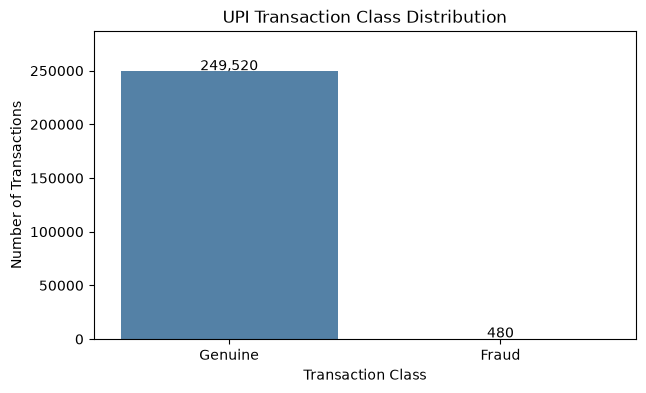

In [6]:
# Fraud class distribution
fraud_counts = df["fraud_flag"].value_counts().sort_index()
fraud_percentages = (
    df["fraud_flag"].value_counts(normalize=True)
    .sort_index() * 100
)

class_summary = pd.DataFrame({
    "Count": fraud_counts,
    "Percentage (%)": fraud_percentages.round(4)
})

class_summary.index = ["Genuine (0)", "Fraud (1)"]

display(class_summary)

# Visualize class imbalance
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=["Genuine", "Fraud"],
    y=fraud_counts.values,
    color="steelblue"
)

for i, count in enumerate(fraud_counts.values):
    ax.text(i, count + 1000, f"{count:,}", ha="center")

plt.title("UPI Transaction Class Distribution")
plt.ylabel("Number of Transactions")
plt.xlabel("Transaction Class")
plt.ylim(0, fraud_counts.max() * 1.15)
plt.show()

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# True fraud labels
y_true = df["fraud_flag"]

# Naive baseline: predict every transaction as genuine
y_pred = np.zeros(len(y_true), dtype=int)

print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_true, y_pred), 4))
print("F1 Score :", round(f1_score(y_true, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy : 0.9981
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0

Confusion Matrix:
[[249520      0]
 [   480      0]]


,transaction type,total_transactions,fraud_count,fraud_rate
3,Recharge,12527,30,0.239483
0,Bill Payment,37368,77,0.206059
1,P2M,87660,167,0.190509
2,P2P,112445,206,0.183201


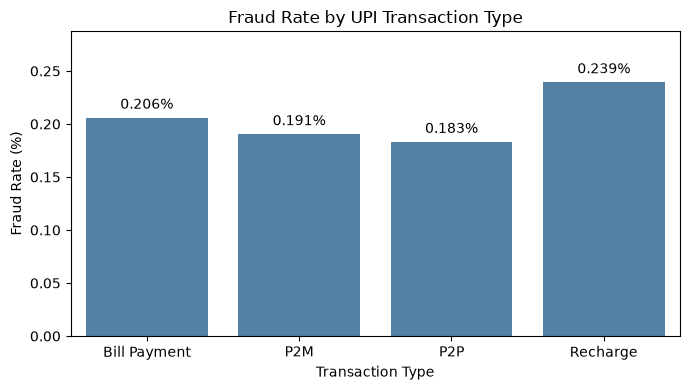

In [8]:
# Fraud analysis by transaction type
type_analysis = (
    df.groupby("transaction type", observed=True)["fraud_flag"]
    .agg(
        total_transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

type_analysis["fraud_rate"] *= 100

type_analysis = type_analysis.sort_values(
    "fraud_rate", ascending=False
)

display(type_analysis)

# Visualization
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    data=type_analysis,
    x="transaction type",
    y="fraud_rate",
    color="steelblue"
)

plt.title("Fraud Rate by UPI Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.3f}%",
        (bar.get_x() + bar.get_width()/2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.ylim(0, type_analysis["fraud_rate"].max() * 1.2)
plt.tight_layout()
plt.show()

### Finding: Fraud by Transaction Type

- Recharge has the highest observed fraud rate (0.239%).
- P2P contributes the most fraud cases (206).
- Fraud rates across transaction types are relatively close.

**Conclusion:** Transaction type alone may not be a strong
fraud predictor. Further model evaluation is required.

,count,mean,median,min,max
Genuine,249520,1311.40,629.0,10,42099
Fraud,480,1499.23,618.5,28,17718


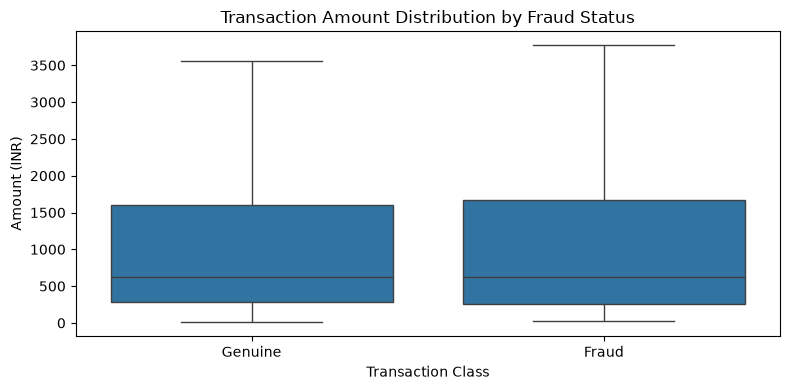

In [9]:
# Compare transaction amounts by fraud class

amount_analysis = (
    df.groupby("fraud_flag")["amount (INR)"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

amount_analysis.index = ["Genuine", "Fraud"]

display(amount_analysis)

# Visualize amount distributions
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df,
    x="fraud_flag",
    y="amount (INR)",
    showfliers=False
)

plt.xticks([0, 1], ["Genuine", "Fraud"])
plt.title("Transaction Amount Distribution by Fraud Status")
plt.xlabel("Transaction Class")
plt.ylabel("Amount (INR)")
plt.tight_layout()
plt.show()

### Finding: Transaction Amount vs Fraud

- Fraud mean amount: ₹1,499.23
- Genuine mean amount: ₹1,311.40
- Fraud median: ₹618.50
- Genuine median: ₹629.00

**Observation:** Fraudulent transactions have a higher
mean amount, but their median is slightly lower.

The amount distributions overlap substantially.

**Conclusion:** Transaction amount alone does not
clearly distinguish fraudulent transactions.

,amount_band,total_transactions,fraud_count,fraud_rate
0,₹0–500,106624,211,0.197892
1,₹501–1000,51037,85,0.166546
2,₹1001–2000,43184,82,0.189885
3,₹2001–5000,38199,69,0.180633
4,₹5000+,10956,33,0.301205


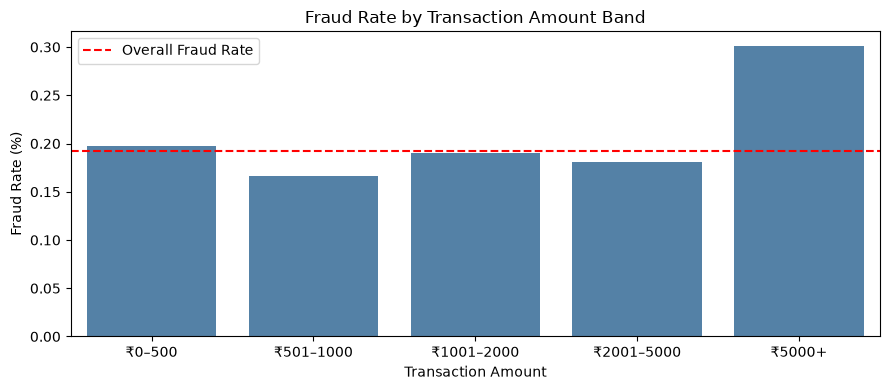

In [10]:
# Create transaction amount bands for EDA
bins = [0, 500, 1000, 2000, 5000, np.inf]

labels = [
    "₹0–500",
    "₹501–1000",
    "₹1001–2000",
    "₹2001–5000",
    "₹5000+"
]

df["amount_band"] = pd.cut(
    df["amount (INR)"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Fraud rate by amount band
amount_band_analysis = (
    df.groupby("amount_band", observed=True)["fraud_flag"]
    .agg(
        total_transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

amount_band_analysis["fraud_rate"] *= 100

display(amount_band_analysis)

# Visualization
plt.figure(figsize=(9, 4))

sns.barplot(
    data=amount_band_analysis,
    x="amount_band",
    y="fraud_rate",
    color="steelblue"
)

plt.axhline(
    df["fraud_flag"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall Fraud Rate"
)

plt.title("Fraud Rate by Transaction Amount Band")
plt.xlabel("Transaction Amount")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

,merchant_category,total_transactions,fraud_count,fraud_rate
8,Transport,20105,43,0.213877
0,Education,7598,16,0.210582
7,Shopping,29872,62,0.207552
6,Other,24828,50,0.201386
1,Entertainment,20103,40,0.198975
2,Food,37464,73,0.194854
3,Fuel,25063,48,0.191517
4,Grocery,49966,94,0.188128
5,Healthcare,12663,21,0.165837
9,Utilities,22338,33,0.147730


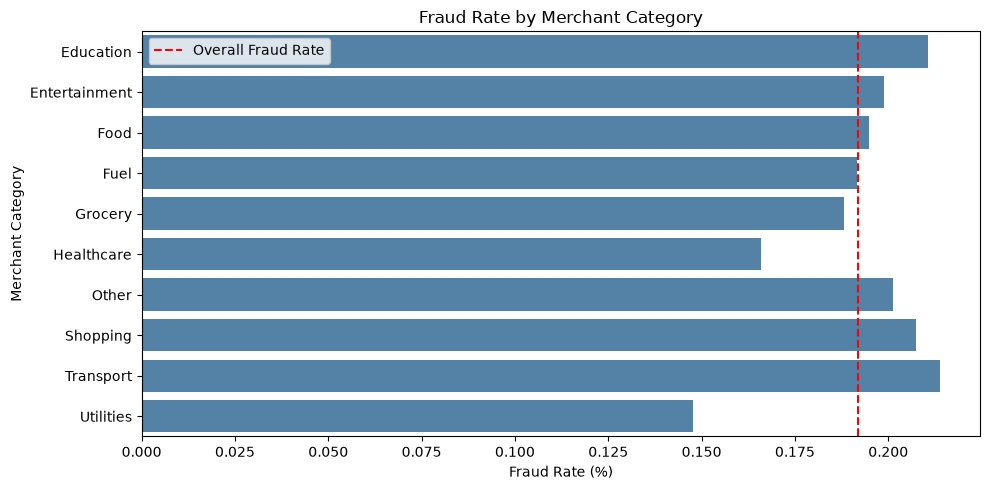

In [11]:
merchant_analysis = (
    df.groupby("merchant_category", observed=True)["fraud_flag"]
    .agg(
        total_transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

merchant_analysis["fraud_rate"] *= 100

merchant_analysis = merchant_analysis.sort_values(
    "fraud_rate", ascending=False
)

display(merchant_analysis)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=merchant_analysis,
    x="fraud_rate",
    y="merchant_category",
    color="steelblue"
)

plt.axvline(
    df["fraud_flag"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall Fraud Rate"
)

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Merchant Category")
plt.legend()
plt.tight_layout()
plt.show()

### Finding: Merchant Category vs Fraud

- Transport and Education show the highest observed fraud rates.
- Utilities has the lowest fraud rate (approximately 0.148%).
- Most merchant categories have fraud rates close to the
  overall dataset fraud rate of 0.192%.

**Conclusion:** Merchant category may contain some risk
information, but its predictive usefulness must be
validated through supervised learning.

,hour_of_day,total_transactions,fraud_count,fraud_rate
0,0,3388,8,0.236128
1,1,2244,6,0.267380
2,2,1685,3,0.178042
3,3,1314,4,0.304414
4,4,1247,1,0.080192
5,5,1742,1,0.057405
6,6,3501,5,0.142816
7,7,5630,13,0.230906
8,8,8349,18,0.215595
9,9,10450,20,0.191388


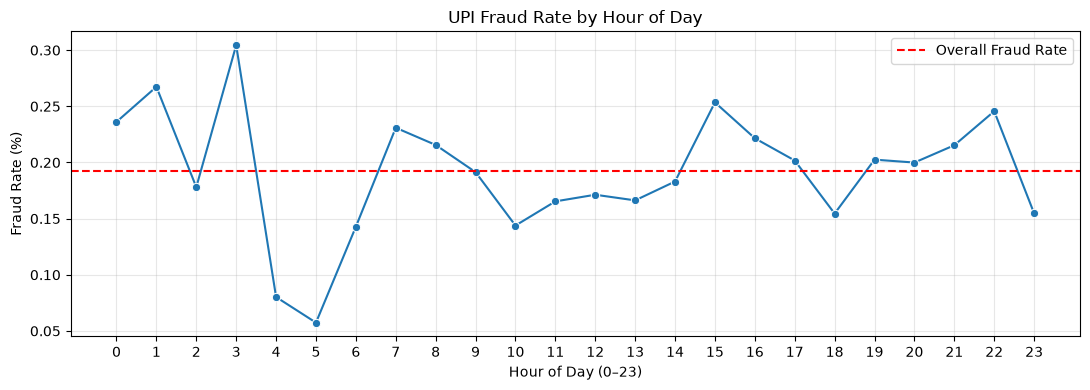

In [12]:
# Fraud analysis by hour of day
hour_analysis = (
    df.groupby("hour_of_day")["fraud_flag"]
    .agg(
        total_transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

hour_analysis["fraud_rate"] *= 100

display(hour_analysis)

# Visualization
plt.figure(figsize=(11, 4))

sns.lineplot(
    data=hour_analysis,
    x="hour_of_day",
    y="fraud_rate",
    marker="o"
)

plt.axhline(
    df["fraud_flag"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall Fraud Rate"
)

plt.xticks(range(24))
plt.title("UPI Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Finding: Fraud Rate by Hour of Day

- 3 AM has the highest observed fraud rate (~0.304%).
- 5 AM has the lowest observed fraud rate (~0.057%).
- Fraud rates fluctuate throughout the day.
- No consistent nighttime fraud pattern is evident.

**Conclusion:** Hour of day may provide useful information,
but observed fluctuations require further validation.

,day_of_week,total_transactions,fraud_count,fraud_rate
0,Monday,36495,71,0.194547
1,Tuesday,35540,58,0.163196
2,Wednesday,35700,75,0.210084
3,Thursday,35432,72,0.203206
4,Friday,35496,61,0.171850
5,Saturday,35334,68,0.192449
6,Sunday,36003,75,0.208316


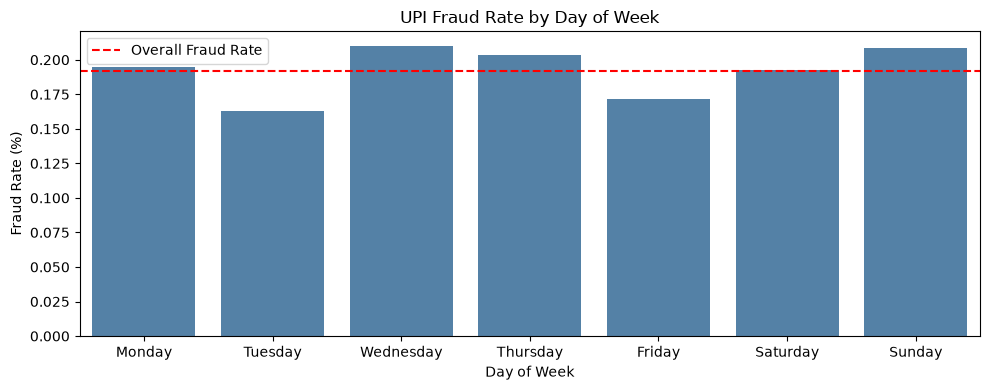

In [13]:
# Fraud rate by day of week

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_analysis = (
    df.groupby("day_of_week", observed=True)["fraud_flag"]
    .agg(
        total_transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reindex(day_order)
    .reset_index()
)

day_analysis["fraud_rate"] *= 100

display(day_analysis)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=day_analysis,
    x="day_of_week",
    y="fraud_rate",
    color="steelblue"
)

plt.axhline(
    df["fraud_flag"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall Fraud Rate"
)

plt.title("UPI Fraud Rate by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# Examine transaction status and fraud relationship

status_analysis = (
    df.groupby("transaction_status", observed=True)["fraud_flag"]
    .agg(
        total_transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

status_analysis["fraud_rate"] *= 100

display(status_analysis)

# Check relationship between status and fraud labels
display(
    pd.crosstab(
        df["transaction_status"],
        df["fraud_flag"],
        normalize="index"
    ).round(4)
)

,transaction_status,total_transactions,fraud_count,fraud_rate
0,FAILED,12376,21,0.169683
1,SUCCESS,237624,459,0.193162


fraud_flag,0,1
transaction_status,,
FAILED,0.9983,0.0017
SUCCESS,0.9981,0.0019


### Finding: Transaction Status and Data Leakage

- FAILED transactions have a fraud rate of 0.170%.
- SUCCESS transactions have a fraud rate of 0.193%.
- The observed difference is small.

**Leakage decision:** Exclude `transaction_status` from
model training because the final transaction outcome
may not be available at prediction time.

`transaction id` will also be excluded from predictors
but retained for transaction tracking.

,amount (INR),hour_of_day,is_weekend,fraud_flag
amount (INR),1.0000,-0.0016,-0.0007,0.0044
hour_of_day,-0.0016,1.0000,0.0015,0.0013
is_weekend,-0.0007,0.0015,1.0000,0.0012
fraud_flag,0.0044,0.0013,0.0012,1.0000


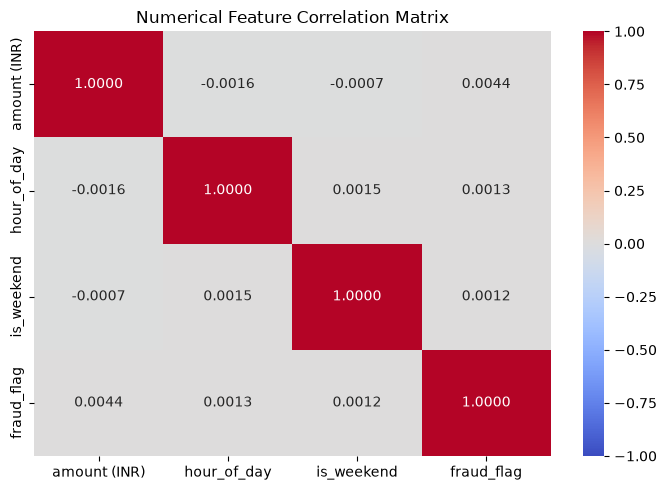

In [15]:
# Numerical features for correlation analysis
numeric_features = [
    "amount (INR)",
    "hour_of_day",
    "is_weekend",
    "fraud_flag"
]

# Calculate Pearson correlations
corr_matrix = df[numeric_features].corr()

display(corr_matrix.round(4))

# Visualize correlations
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".4f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### Finding: Numerical Feature Correlation

- Amount vs Fraud: +0.0044
- Hour vs Fraud: +0.0013
- Weekend vs Fraud: +0.0012

All three features show negligible linear correlation
with the fraud target.

**Conclusion:** Numerical features alone may offer limited
linear predictive information. Nonlinear relationships and
categorical features require further investigation.

,Feature,Cramers_V,p_value
2,sender_age_group,0.00533,0.02551
3,receiver_age_group,0.00366,0.11840
5,sender_bank,0.00297,0.23841
0,transaction type,0.00000,0.50799
1,merchant_category,0.00000,0.91316
4,sender_state,0.00000,0.55804
6,receiver_bank,0.00000,0.96906
7,device_type,0.00000,0.79592
8,network_type,0.00000,0.43535
9,day_of_week,0.00000,0.72458


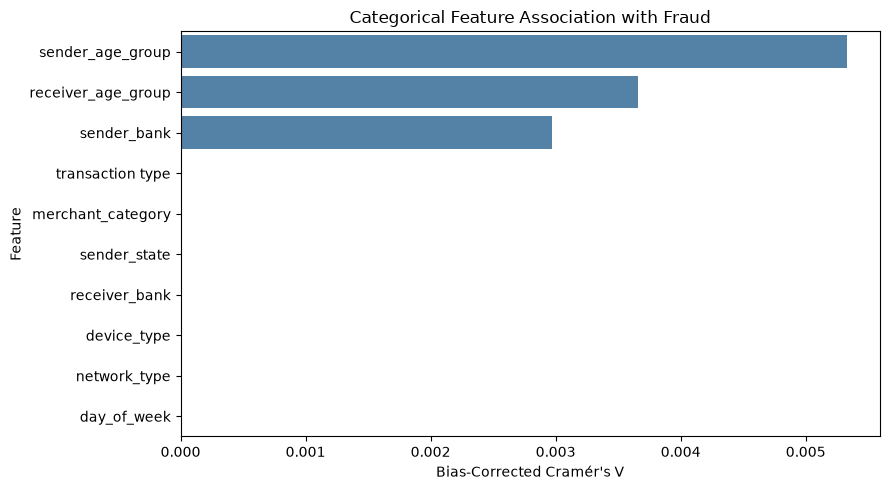

In [16]:
from scipy.stats import chi2_contingency

cat_cols = [
    "transaction type",
    "merchant_category",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "day_of_week"
]

results = []

for col in cat_cols:
    table = pd.crosstab(df[col], df["fraud_flag"])

    chi2, p, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    r, k = table.shape

    # Bias-corrected Cramér's V
    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(k_corr - 1, r_corr - 1)

    cramers_v = np.sqrt(
        phi2_corr / denominator
    ) if denominator > 0 else 0

    results.append({
        "Feature": col,
        "Cramers_V": cramers_v,
        "p_value": p
    })

association_df = pd.DataFrame(results).sort_values(
    "Cramers_V", ascending=False
)

display(association_df.round(5))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=association_df,
    x="Cramers_V",
    y="Feature",
    color="steelblue"
)

plt.title("Categorical Feature Association with Fraud")
plt.xlabel("Bias-Corrected Cramér's V")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [17]:
print("Sender banks:")
print(df["sender_bank"].value_counts())

print("\nReceiver banks:")
print(df["receiver_bank"].value_counts())

print("\nBank association with fraud:")
display(
    association_df[
        association_df["Feature"].isin(
            ["sender_bank", "receiver_bank"]
        )
    ]
)

Sender banks:
sender_bank
SBI         62693
HDFC        37485
ICICI       29769
IndusInd    25173
Axis        25042
PNB         24946
Yes Bank    24860
Kotak       20032
Name: count, dtype: int64

Receiver banks:
receiver_bank
SBI         62378
HDFC        37651
ICICI       29944
IndusInd    25086
Yes Bank    25009
Axis        24992
PNB         24802
Kotak       20138
Name: count, dtype: int64

Bank association with fraud:


,Feature,Cramers_V,p_value
5,sender_bank,0.002968,0.238414
6,receiver_bank,0.000000,0.969061


### Finding: Bank Association with Fraud

- Sender bank: Cramér's V = 0.00297, p = 0.2384
- Receiver bank: Cramér's V = 0.00000, p = 0.9691

Neither bank feature shows a statistically significant
association with fraud at the 5% significance level.

**Conclusion:** Bank identity alone provides little evidence
of fraud risk in this dataset. Both features will be retained
as candidates for supervised model evaluation.

In [18]:
bank_analysis = (
    df.groupby("sender_bank", observed=True)["fraud_flag"]
    .agg(
        total_transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .sort_values("fraud_rate", ascending=False)
)

bank_analysis["fraud_rate"] *= 100

display(bank_analysis.round(4))

,total_transactions,fraud_count,fraud_rate
sender_bank,,,
Kotak,20032,50,0.2496
ICICI,29769,66,0.2217
PNB,24946,52,0.2085
IndusInd,25173,52,0.2066
Axis,25042,49,0.1957
SBI,62693,109,0.1739
HDFC,37485,62,0.1654
Yes Bank,24860,40,0.1609


## EDA Summary — Key Findings & ML Implications

### 1. Data Quality
- Dataset contains **250,000 transactions and 17 original columns**.
- No missing values, duplicate records, or invalid values were found in our checks.
- Data types were optimized for analysis.
- `transaction_status` was identified as a potential leakage feature because it may be unavailable before payment approval.

**ML Implication:** The dataset is suitable for modelling after finalizing feature eligibility and leakage exclusions.

### 2. Severe Class Imbalance
- Genuine: **249,520 (99.808%)**
- Fraud: **480 (0.192%)**
- A model predicting every transaction as genuine achieves 99.808% accuracy but 0% fraud recall.

**ML Implication:** Accuracy is insufficient. Prioritize PR-AUC, recall, precision and F1-score. Compare class weights and training-only SMOTE.

### 3. Transaction Type & Merchant Category
- Recharge has the highest observed transaction-type fraud rate (0.239%).
- P2P contributes the highest fraud count (206).
- Transport and Education have relatively high observed merchant-category fraud rates.
- Differences across categories are generally small.

**ML Implication:** Retain transaction type and merchant category as candidate predictors, but validate whether they improve performance.

### 4. Transaction Amount
- Average fraud amount: **₹1,499.23**
- Average genuine amount: **₹1,311.40**
- Median fraud amount: **₹618.50**
- Median genuine amount: **₹629**
- Transactions above ₹5,000 show the highest observed fraud rate among the examined amount bands.
- Amount distributions substantially overlap.

**ML Implication:** Transaction amount may provide nonlinear predictive information, but amount alone cannot reliably identify fraud.

### 5. Time-Based Patterns
- Highest observed hourly fraud rate: approximately 0.304% at 3 AM.
- Lowest observed hourly fraud rate: approximately 0.057% at 5 AM.
- No consistent nighttime fraud pattern was established.

**ML Implication:** Retain time-related features for evaluation while recognizing that hourly differences may reflect sampling variation.

### 6. Numerical Correlations
| Feature | Correlation with Fraud |
|---|---:|
| Amount | 0.0044 |
| Hour of day | 0.0013 |
| Weekend indicator | 0.0012 |

All measured numerical correlations with fraud are extremely weak.

**ML Implication:** Linear relationships appear limited. Nonlinear models and feature interactions should be evaluated without assuming they will improve performance.

### 7. Categorical Associations
- Sender age group has the highest measured bias-corrected Cramér's V (approximately 0.0053).
- Sender bank association: 0.00297, p = 0.2384.
- Receiver bank association: 0.00000, p = 0.9691.
- Overall categorical associations with fraud are very weak.

**ML Implication:** No individual categorical feature demonstrates a strong association with fraud. Keep candidate predictors initially and evaluate their predictive contribution on validation data.

### 8. Key Limitations
- Only 480 fraud cases are available.
- Observed differences do not establish causation.
- Weak individual associations do not rule out feature interactions.
- The available features may not contain enough information for reliable fraud detection.
- The data is simulated, so real-world performance cannot be assumed.

---

### Final EDA Conclusion

The dataset is highly imbalanced, and most available transaction features show weak individual relationships with fraud.

Our supervised ML phase will compare **Logistic Regression, Random Forest, and XGBoost/Gradient Boosting**, evaluate class-weighting and SMOTE, and select a model using appropriate validation metrics rather than accuracy alone.

The final objective is to generate reliable fraud risk scores that can support cost-based **Approve / OTP / Block** decisions.

**Next Phase:** Feature eligibility → Data splitting → Preprocessing → Supervised model training → Evaluation.

,month,total_transactions,fraud_count,fraud_rate
0,1,21221,50,0.2356
1,2,19759,34,0.1721
2,3,21234,47,0.2213
3,4,20536,33,0.1607
4,5,21333,37,0.1734
5,6,20628,30,0.1454
6,7,21207,52,0.2452
7,8,21231,33,0.1554
8,9,20597,42,0.2039
9,10,21252,45,0.2117


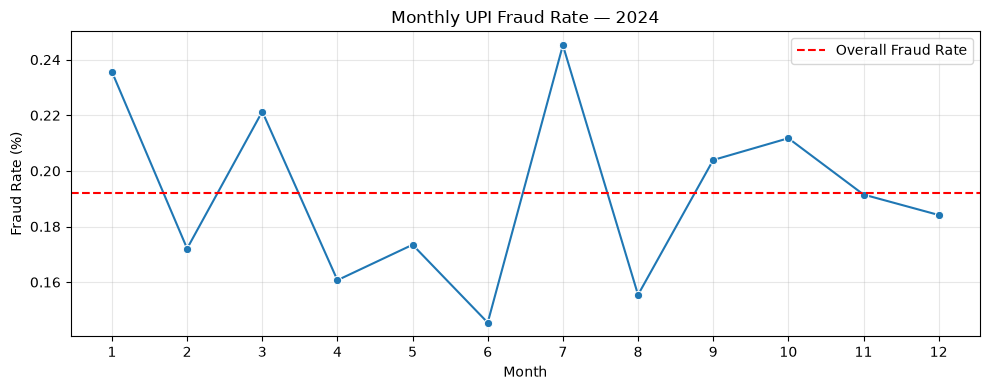

In [20]:
# Extract month from timestamp
df["month"] = df["timestamp"].dt.month

# Monthly fraud analysis
monthly_analysis = (
    df.groupby("month")["fraud_flag"]
    .agg(
        total_transactions="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

monthly_analysis["fraud_rate"] *= 100

display(monthly_analysis.round(4))

# Visualization
plt.figure(figsize=(10, 4))

sns.lineplot(
    data=monthly_analysis,
    x="month",
    y="fraud_rate",
    marker="o"
)

plt.axhline(
    df["fraud_flag"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall Fraud Rate"
)

plt.xticks(range(1, 13))
plt.title("Monthly UPI Fraud Rate — 2024")
plt.xlabel("Month")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# Columns excluded from model input
exclude_cols = [
    "transaction id",       # Identifier, not a predictor
    "transaction_status",   # Potential post-transaction leakage
    "fraud_flag",           # Target variable
    "timestamp",            # Retained for splitting
    "amount_band"           # EDA-only feature
]

# Ensure month is available
df["month"] = df["timestamp"].dt.month

# Select candidate ML features
feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

target_col = "fraud_flag"

# Prepare features and target
X = df[feature_cols].copy()
y = df[target_col].copy()

print("Number of candidate features:", len(feature_cols))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

# Display selected features and data types
display(pd.DataFrame({
    "Feature": feature_cols,
    "Data Type": [str(df[col].dtype) for col in feature_cols]
}))

Number of candidate features: 14
Feature matrix shape: (250000, 14)
Target shape: (250000,)


,Feature,Data Type
0,transaction type,category
1,merchant_category,category
2,amount (INR),int64
3,sender_age_group,category
4,receiver_age_group,category
5,sender_state,category
6,sender_bank,category
7,receiver_bank,category
8,device_type,category
9,network_type,category


In [22]:
# Export EDA-ready dataset

# Remove EDA-only amount band
df_export = df.drop(
    columns=["amount_band"],
    errors="ignore"
).copy()

# Save dataset
df_export.to_csv(
    "upi_eda_ready.csv",
    index=False
)

print("Dataset exported successfully!")
print("Shape:", df_export.shape)
print("Columns:", df_export.columns.tolist())

Dataset exported successfully!
Shape: (250000, 18)
Columns: ['transaction id', 'timestamp', 'transaction type', 'merchant_category', 'amount (INR)', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend', 'month']
